<div style="border-bottom:3px solid #2c3e50;padding-bottom:10px;margin-bottom:10px">
<h1 style="color:#2c3e50;margin:0">Switching optimal pour le stockage de gaz — algorithme BLSM</h1>
<p style="color:#7f8c8d;margin:5px 0 0 0">Backward Longstaff–Schwartz à régression découplée (sans biais de clairvoyance)<br>
Reproduction Carmona &amp; Ludkovski (2010), <i>Quantitative Finance</i></p>
</div>

**Structure du notebook**

- **Corps principal** : moteur, validation chiffrée (Tables 3 et 4 de Carmona–Ludkovski), figures.
- **Annexe** : diagnostics et études de sensibilité (coûteux, optionnels).

**Principe méthodologique.** La phase *backward* régresse uniquement l'espérance de continuation
$\mathbb{E}[V_{t+\Delta t}\,|\,\mathcal{F}_t]$ (coefficients `cont_coefs`). La phase *forward* re-simule
des trajectoires indépendantes et décide en lisant ces coefficients **au prix présent** $G_m$, sans jamais
consulter $G_{m+1}$. Ce découplage élimine le biais de clairvoyance (*look-ahead*).

## 1. Le moteur BLSM (régression découplée)

Trois estimateurs partagent le même *backward* :
- **TViR** : valeur ponctuelle au point initial (in-sample, sensible).
- **BLSM-forward** : moyenne Monte-Carlo sur trajectoires indépendantes (estimateur principal, borne inférieure propre).

`value_forward_vec(..., record=True)` expose en plus la trace des états $(g,c)$ visités, utilisée par les figures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
REG=(-1,0,1)

def train_backward(phys,cfg,rng,use_quasi=False):
    """Backward LSM découplé. Renvoie cont_coefs[j][m] = coefficients de
    l'espérance de continuation E[V_{m+1}|F_m] (actualisée), régressée sur
    la base évaluée au PRÉSENT g_m. Aucune information future dans la décision."""
    M,N,ng=cfg["M"],cfg["N"],cfg["n_grid"]
    dt=phys["T"]/M; disc=np.exp(-phys["r"]*dt)
    G=phys["simulate"](M,N,rng); cg=np.linspace(0,phys["C_max"],ng)
    if use_quasi:
        Cq={i:np.empty((M+1,N)) for i in REG}
        for i in REG: Cq[i][M]=rng.uniform(0,phys["C_max"],N)
    coefs={i:[None]*M for i in REG}        # enveloppe de Snell (interne au backward)
    cont_coefs={i:[None]*M for i in REG}   # espérance de continuation pure (sortie)
    for m in range(M-1,-1,-1):
        gG=np.repeat(G[m],ng); cG=np.tile(cg,N); gnG=np.repeat(G[m+1],ng)
        if use_quasi:
            for i in REG: Cq[i][m]=phys["invert"](i,Cq[i][m+1],dt)
            g_all=np.concatenate([gG]+[G[m]]*3); c_all=np.concatenate([cG]+[Cq[i][m] for i in REG]); gn_all=np.concatenate([gnG]+[G[m+1]]*3)
        else:
            g_all,c_all,gn_all=gG,cG,gnG
        Phi=phys["basis"](g_all,c_all,m*dt)
        A=Phi.T@Phi+cfg["ridge"]*np.eye(Phi.shape[1])
        # (1) Continuation pure : on régresse la valeur FUTURE sur la base PRÉSENTE.
        for j in REG:
            V_next = phys["terminal"](gn_all, c_all) if m==M-1 else phys["basis"](gn_all, c_all, (m+1)*dt)@coefs[j][m+1]
            cont_coefs[j][m] = np.linalg.solve(A, Phi.T @ (disc * V_next))
        # (2) Enveloppe de Snell (sert uniquement à propager le backward).
        for i in REG:
            best=None
            for j in REG:
                cf,cn=phys["step"](j,g_all,c_all,dt); sw=phys["K_switch"] if i!=j else 0.0
                cont = phys["basis"](g_all, cn, m*dt) @ cont_coefs[j][m]
                q = cf - sw + cont
                best = q if best is None else np.maximum(best, q)
            coefs[i][m] = np.linalg.solve(A, Phi.T @ best)
    return cont_coefs

def value_forward_vec(phys,cont_coefs,cfg,rng,record=False):
    """Forward out-of-sample. Décision au pas m : lit cont_coefs[j][m] évalué
    en G[m] (jamais G[m+1]). Si record=True, renvoie aussi la trace des états."""
    M,N=cfg["M"],cfg["N_eval"]; dt=phys["T"]/M; disc=np.exp(-phys["r"]*dt)
    G=phys["simulate"](M,N,rng); c=np.full(N,phys["C0"]); regime=np.full(N,phys["regime0"]); pv=np.zeros(N); df=1.0
    if record:
        rec_g=np.empty((M,N)); rec_c=np.empty((M,N)); rec_r=np.empty((M,N))
    for m in range(M):
        qs=np.empty((3,N)); cfs=np.empty((3,N)); cns=np.empty((3,N))
        for k,j in enumerate(REG):
            cf,cn=phys["step"](j,G[m],c,dt)
            expected_cont = phys["basis"](G[m], cn, m*dt) @ cont_coefs[j][m]   # actualisation déjà incluse
            sw=np.where(regime==j,0.0,phys["K_switch"])
            qs[k]=cf-sw+expected_cont; cfs[k]=cf-sw; cns[k]=cn
        b=qs.argmax(0); idx=np.arange(N)
        if record: rec_g[m]=G[m]; rec_c[m]=c; rec_r[m]=regime   # état AVANT décision du pas m
        pv+=df*cfs[b,idx]; c=cns[b,idx]; regime=np.array(REG)[b]; df*=disc
    pv+=df*phys["terminal"](G[M],c)
    if record: return pv,{"g":rec_g,"c":rec_c,"regime":rec_r}
    return pv

def value_tvr(phys,cont_coefs):
    """Valeur ponctuelle au point initial (g0,c0,regime0) : max sur les actions."""
    g0=np.array([phys["price0"]]); c0=np.array([phys["C0"]]); i_0=phys["regime0"]
    dt=phys["T"]/len(cont_coefs[-1])
    best=-np.inf
    for j in (-1,0,1):
        cf,cn=phys["step"](j,g0,c0,dt); sw=phys["K_switch"] if i_0!=j else 0.0
        cont=phys["basis"](g0,cn,0.0)@cont_coefs[j][0]
        q=(cf-sw+cont)[0]
        if q>best: best=q
    return float(best)

def stats(pv):
    m=pv.mean(); sd=pv.std(ddof=1); return m, sd, 1.96*sd/np.sqrt(len(pv))  # moy, SD, demi-IC95
def set_degree(p,deg): p["_deg"]=deg; return p

## 2. Physique — Exemple 1 (prix log-OU)

Prix mean-reverting en log (Ornstein–Uhlenbeck), débits d'injection/soutirage constants, coût de stockage proportionnel à l'inventaire. Base de régression : polynômes bivariés en $(\log g,\ c)$ de degré total `_deg`.

In [2]:
def make_ex1(p):
    def simulate(M,N,rng):
        dt=p["T"]/M; G=np.empty((M+1,N)); G[0]=np.log(p["G0"])
        decay=np.exp(-p["kappa"]*dt); lt=np.log(p["theta"]); vol=p["sigma"]*np.sqrt((1-decay**2)/(2*p["kappa"]))
        Z=rng.standard_normal((M,N))
        for m in range(M): G[m+1]=G[m]*decay+lt*(1-decay)+vol*Z[m]
        return np.exp(G)
    def basis(g,c,t):
        x=np.log(np.maximum(g,1e-8)); y=np.asarray(c,float); cols=[np.ones_like(x)]
        for d in range(1,p["_deg"]+1):
            for i in range(d+1): cols.append(x**(d-i)*y**i)
        return np.column_stack(cols)
    def terminal(g,c): return -2.0*g*np.maximum(4.0-c,0.0)
    def step(r,g,c,dt):
        sc=p["k_store"]*c*dt
        if r==-1: rate=np.minimum(p["a_in"],(p["C_max"]-c)/dt); return -rate*g*dt-sc, np.clip(c+rate*dt,0,p["C_max"])
        if r==1:  rate=np.minimum(p["a_out"],c/dt); return rate*g*dt-sc, np.clip(c-rate*dt,0,p["C_max"])
        return -sc, np.asarray(c,float).copy()
    def invert(r,c_next,dt):
        if r==-1: return np.clip(c_next-p["a_in"]*dt,0,p["C_max"])
        if r==1:  return np.clip(c_next+p["a_out"]*dt,0,p["C_max"])
        return c_next.copy()
    return {"simulate":simulate,"basis":basis,"terminal":terminal,"step":step,"invert":invert,
            "C_max":p["C_max"],"C0":p["C0"],"r":p["r"],"T":p["T"],"K_switch":p["K_switch"],"regime0":0,"price0":p["G0"]}

def adaptive_M(ain,aout):
    a=max(ain,aout)*365; return int(np.clip(a*20/8,200,400)//50*50)

BASE={"kappa":17.1,"theta":3.0,"sigma":1.33,"G0":3.0,"C_max":8.0,"C0":4.0,
      "k_store":0.1,"K_switch":0.25,"r":0.06,"T":1.0}

### Vérification : neutralité du mode `record`

Le mode `record=True` ne doit pas altérer les valeurs (même graine ⇒ même résultat).

In [3]:
_P=dict(BASE,a_in=0.06*365,a_out=0.25*365); set_degree(_P,4); _phys=make_ex1(_P)
_cfg={"M":200,"N":1500,"N_eval":6000,"n_grid":25,"degree":4,"ridge":1e-4}
_cc=train_backward(_phys,_cfg,np.random.default_rng(83),use_quasi=False)
_a=value_forward_vec(_phys,_cc,_cfg,np.random.default_rng(84))
_b,_tr=value_forward_vec(_phys,_cc,_cfg,np.random.default_rng(84),record=True)
print("record neutre :", np.allclose(_a,_b), "| forward=%.3f  tvir=%.3f"%(_a.mean(),value_tvr(_phys,_cc)))

record neutre : True | forward=9.308  tvir=9.228


## 3. Table 3 — Validation sur trois jeux de débits

Reproduction des trois configurations de référence. Colonne **cible** = valeur Carmona–Ludkovski. On reporte le **forward** (estimateur principal, ± IC95) et le **TViR** (valeur ponctuelle).

In [4]:
TABLE3=[(0.06,0.25,9.35),(0.03,0.125,4.75),(0.12,0.25,12.33)]
DEG=4
print(f"{'a_in':>5}{'a_out':>7}{'cible':>7} | {'BLSM-forward':>20} | {'TViR':>14}")
print("-"*54)
for ain,aout,tgt in TABLE3:
    p=dict(BASE,a_in=ain*365,a_out=aout*365); set_degree(p,DEG); phys=make_ex1(p)
    cfg={"M":adaptive_M(ain,aout),"N":2000,"N_eval":8000,"n_grid":30,"degree":DEG,"ridge":1e-4}
    cc=train_backward(phys,cfg,np.random.default_rng(83),use_quasi=False)
    mg,_,icg=stats(value_forward_vec(phys,cc,cfg,np.random.default_rng(84)))
    vt=value_tvr(phys,cc)
    print(f"{ain:>5}{aout:>7}{tgt:>7.2f} | {mg:>7.2f} ± {icg:>4.2f} ({abs(mg-tgt)/tgt*100:>4.1f}%) | {vt:>7.2f} ({abs(vt-tgt)/tgt*100:>4.1f}%)")

 a_in  a_out  cible |         BLSM-forward |           TViR
------------------------------------------------------
 0.06   0.25   9.35 |    9.29 ± 0.09 ( 0.6%) |    9.25 ( 1.1%)
 0.03  0.125   4.75 |    4.47 ± 0.06 ( 5.9%) |    3.94 (17.0%)
 0.12   0.25  12.33 |   12.60 ± 0.11 ( 2.2%) |   12.44 ( 0.9%)


## 4. Table 4 — Effet des caractéristiques d'ingénierie

Sensibilité de $V(0,3,4,0)$ à trois paramètres, un à la fois (débits de référence $a_{in}=0.06,\ a_{out}=0.25$). On vérifie surtout les **monotonies** attendues : $V$ croît avec la capacité, décroît avec le coût de switch, décroît avec le coût de stockage.

In [5]:
A_IN, A_OUT = 0.06, 0.25
def eval_point(overrides):
    p=dict(BASE, a_in=A_IN*365, a_out=A_OUT*365, **overrides)
    set_degree(p,4); phys=make_ex1(p)
    cfg={"M":adaptive_M(A_IN,A_OUT),"N":2000,"N_eval":8000,"n_grid":30,"degree":4,"ridge":1e-4}
    cc=train_backward(phys,cfg,np.random.default_rng(83),use_quasi=False)
    mf,_,ic=stats(value_forward_vec(phys,cc,cfg,np.random.default_rng(84)))
    return value_tvr(phys,cc), mf, ic

BLOCS=[
  ("Effet de la capacité (C_max)","C_max",
    [(6,7.78),(8,9.35),(10,10.26),(12,10.58)], lambda v:{"C_max":float(v)}),
  ("Effet du coût de switch (K_switch)","K_sw",
    [(0.01,13.25),(0.1,11.40),(0.25,9.35),(0.5,6.73)], lambda v:{"K_switch":float(v)}),
  ("Effet du coût de stockage (k_store)","k_st",
    [(0.0,9.77),(0.05,9.56),(0.1,9.35)], lambda v:{"k_store":float(v)}),
]
for titre,label,lignes,mk in BLOCS:
    print(f"\n{titre}")
    print(f"{label:>8}{'cible':>8}{'TViR':>9}{'(éc.)':>8}{'forward':>10}{'(éc.)':>8}")
    print("-"*51)
    for val,cible in lignes:
        vt,mf,ic=eval_point(mk(val))
        print(f"{val:>8}{cible:>8.2f}{vt:>9.2f}{abs(vt-cible)/cible*100:>7.1f}%{mf:>9.2f}{abs(mf-cible)/cible*100:>7.1f}%")


Effet de la capacité (C_max)
   C_max   cible     TViR   (éc.)   forward   (éc.)
---------------------------------------------------
       6    7.78     8.03    3.2%     7.96    2.3%
       8    9.35     9.25    1.1%     9.29    0.6%
      10   10.26     9.44    8.0%    10.15    1.0%
      12   10.58     9.69    8.4%    10.36    2.1%

Effet du coût de switch (K_switch)
    K_sw   cible     TViR   (éc.)   forward   (éc.)
---------------------------------------------------
    0.01   13.25    13.36    0.8%    12.80    3.4%
     0.1   11.40    11.34    0.5%    11.12    2.4%
    0.25    9.35     9.25    1.1%     9.29    0.6%
     0.5    6.73     6.94    3.2%     7.01    4.1%

Effet du coût de stockage (k_store)
    k_st   cible     TViR   (éc.)   forward   (éc.)
---------------------------------------------------
     0.0    9.77     9.68    0.9%     9.72    0.5%
    0.05    9.56     9.46    1.0%     9.51    0.6%
     0.1    9.35     9.25    1.1%     9.29    0.6%


In [8]:
# === CALCUL (une fois) : continuation vs fonction valeur, cas Carmona 0.06/0.25 ===
_Pv=dict(BASE, a_in=0.06*365, a_out=0.25*365); set_degree(_Pv,4); _physv=make_ex1(_Pv)
_cfgv={"M":250,"N":2000,"N_eval":8000,"n_grid":30,"degree":4,"ridge":1e-4}
_ccv=train_backward(_physv,_cfgv,np.random.default_rng(83),use_quasi=False)
_TS=0.5; _mt=max(0,min(_cfgv["M"]-1,int(round(_TS/(_physv["T"]/_cfgv["M"]))))); _dtv=_physv["T"]/_cfgv["M"]

def _continuation(g,c):                       # valeur d'attendre (régime store)
    return _physv["basis"](g,c,_TS)@_ccv[0][_mt]
def _valueV(g,c):                             # valeur optimale = max sur les 3 actions
    qs=[]
    for j in (-1,0,1):
        cf,cn=_physv["step"](j,g,c,_dtv)
        qs.append(cf + _physv["basis"](g,cn,_TS)@_ccv[j][_mt])
    return np.max(qs,axis=0)

# Grille pour les surfaces
_g=np.linspace(1,7,60); _c=np.linspace(0,_physv["C_max"],60); _GG,_CC=np.meshgrid(_g,_c)
_VC=_continuation(_GG.ravel(),_CC.ravel()).reshape(_GG.shape)
_VV=_valueV(_GG.ravel(),_CC.ravel()).reshape(_GG.shape)

# Coupes 1D pré-calculées (continuation + V à 3 inventaires)
_COUPES={}
for cval in (1.0,4.0,7.0):
    _ca=np.full_like(_g,cval)
    _COUPES[cval]=(_continuation(_g,_ca), _valueV(_g,_ca))

print("Calcul OK. V >= continuation partout :", np.all(_VV>=_VC-1e-6),
      "| prime de switch moyenne = %.3f"%(_VV-_VC).mean())


# Écart V - continuation (= prime de flexibilité de switch) + prix d'indifférence
_ECART={}
for cval in (1.0,4.0,7.0):
    _ca=np.full_like(_g,cval)
    e=_valueV(_g,_ca)-_continuation(_g,_ca)
    _ECART[cval]=(e, _g[e.argmin()])     # (courbe d'écart, prix d'indifférence = argmin)
print("Prix d'indifférence (min de la prime) :",
      {c:round(float(_ECART[c][1]),2) for c in _ECART})

Calcul OK. V >= continuation partout : True | prime de switch moyenne = 0.508
Prix d'indifférence (min de la prime) : {1.0: 3.85, 4.0: 3.54, 7.0: 3.24}


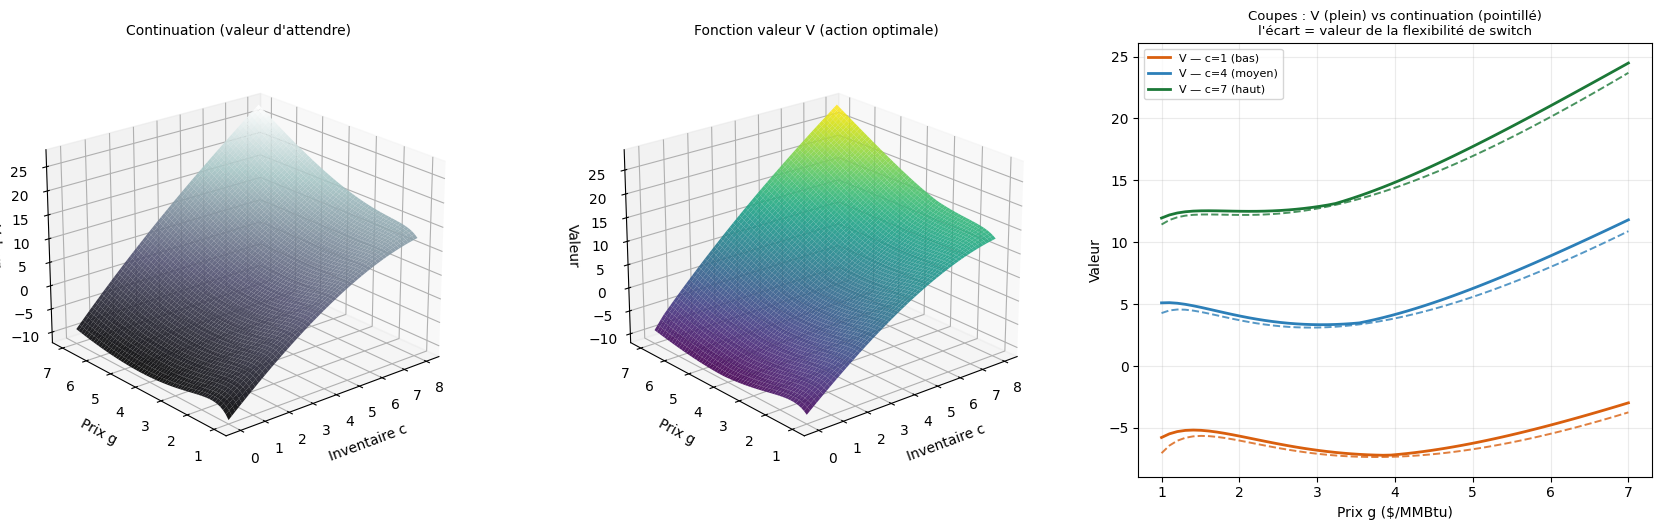

In [7]:
# === AFFICHAGE (rejouable) : ne lit que _GG,_CC,_VC,_VV,_g,_COUPES déjà calculés ===
from mpl_toolkits.mplot3d import Axes3D

fig=plt.figure(figsize=(17,5.4))
# Gauche : surface continuation
ax1=fig.add_subplot(1,3,1,projection="3d")
ax1.plot_surface(_CC,_GG,_VC,cmap="bone",edgecolor="none",alpha=0.9,rstride=1,cstride=1)
ax1.set_xlabel("Inventaire c",labelpad=6); ax1.set_ylabel("Prix g",labelpad=6); ax1.set_zlabel("Valeur",labelpad=2)
ax1.set_title("Continuation (valeur d'attendre)",fontsize=10); ax1.view_init(elev=22,azim=-130)
# Milieu : surface fonction valeur
ax2=fig.add_subplot(1,3,2,projection="3d")
ax2.plot_surface(_CC,_GG,_VV,cmap="viridis",edgecolor="none",alpha=0.9,rstride=1,cstride=1)
ax2.set_xlabel("Inventaire c",labelpad=6); ax2.set_ylabel("Prix g",labelpad=6); ax2.set_zlabel("Valeur",labelpad=2)
ax2.set_title("Fonction valeur V (action optimale)",fontsize=10); ax2.view_init(elev=22,azim=-130)
# Droite : coupes 1D
ax3=fig.add_subplot(1,3,3)
for cval,col,lab in [(1.0,"#d95f0e","c=1 (bas)"),(4.0,"#2c7fb8","c=4 (moyen)"),(7.0,"#1b7837","c=7 (haut)")]:
    vc,vv=_COUPES[cval]
    ax3.plot(_g,vv,color=col,lw=2.0,label=f"V — {lab}")
    ax3.plot(_g,vc,color=col,lw=1.4,ls="--",alpha=0.8)
ax3.set_xlabel("Prix g ($/MMBtu)"); ax3.set_ylabel("Valeur")
ax3.set_title("Coupes : V (plein) vs continuation (pointillé)\nl'écart = valeur de la flexibilité de switch",fontsize=9.5)
ax3.legend(fontsize=8,loc="upper left"); ax3.grid(alpha=.25)
plt.tight_layout(); plt.show()

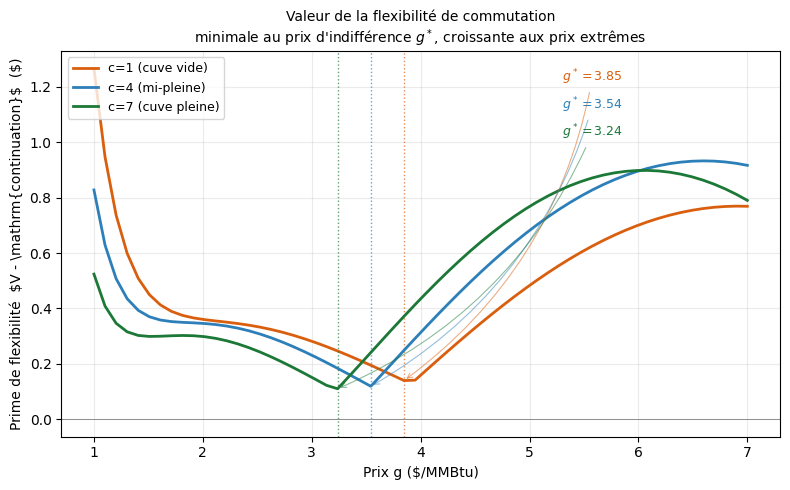

In [30]:
# === AFFICHAGE prime de switch (rejouable) : lit _g, _ECART ===
fig, ax = plt.subplots(figsize=(8, 5))

series = [(1.0, "#d95f0e", "c=1 (cuve vide)"),
          (4.0, "#2c7fb8", "c=4 (mi-pleine)"),
          (7.0, "#1b7837", "c=7 (cuve pleine)")]

# annotations dans le coin HAUT-DROITE (zone vide), étagées verticalement
ann_x = 5.3
y_levels = [1.22, 1.12, 1.02]

for (cval, col, lab), y_ann in zip(series, y_levels):
    e, gstar = _ECART[cval]
    ax.plot(_g, e, color=col, lw=2.0, label=lab)
    ax.axvline(gstar, color=col, ls=":", lw=1.0, alpha=0.7)
    ax.annotate(f"$g^*={gstar:.2f}$",
                xy=(gstar, e.min()),
                xytext=(ann_x, y_ann),
                fontsize=9, color=col, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color=col, lw=0.8, alpha=0.5,
                                connectionstyle="arc3,rad=-0.2"))

ax.set_xlabel("Prix g ($/MMBtu)")
ax.set_ylabel("Prime de flexibilité  $V - \\mathrm{continuation}$  ($)")
ax.set_title("Valeur de la flexibilité de commutation\n"
             "minimale au prix d'indifférence $g^*$, croissante aux prix extrêmes",
             fontsize=10)
ax.axhline(0, color="grey", lw=0.6)
ax.legend(fontsize=9, loc="upper left")
ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

In [ ]:
# =====================================================================
#  Continuation vs Fonction valeur (Exemple 1, degré 4, cas Carmona 0.06/0.25)
#  - Gauche  : surface de la continuation au régime "store" (valeur d'attendre)
#  - Milieu  : surface de la vraie fonction valeur V = max_j (cashflow_j + cont_j)
#  - Droite  : 3 coupes 1D à inventaire fixe, où l'écart V - continuation
#              (= valeur de la flexibilité de switch) se lit directement.
#  Tout est lu depuis cont_coefs : aucune décision ré-implémentée.
# =====================================================================
from mpl_toolkits.mplot3d import Axes3D

_Pv=dict(BASE, a_in=0.06*365, a_out=0.25*365); set_degree(_Pv,4); _physv=make_ex1(_Pv)
_cfgv={"M":250,"N":2000,"N_eval":8000,"n_grid":30,"degree":4,"ridge":1e-4}
_ccv=train_backward(_physv,_cfgv,np.random.default_rng(83),use_quasi=False)
_TS=0.5; _mt=max(0,min(_cfgv["M"]-1,int(round(_TS/(_physv["T"]/_cfgv["M"]))))); _dtv=_physv["T"]/_cfgv["M"]

def _continuation(g,c):                       # valeur d'attendre (régime store)
    return _physv["basis"](g,c,_TS)@_ccv[0][_mt]
def _valueV(g,c):                             # valeur optimale = max sur les 3 actions
    qs=[]
    for j in (-1,0,1):
        cf,cn=_physv["step"](j,g,c,_dtv)
        qs.append(cf + _physv["basis"](g,cn,_TS)@_ccv[j][_mt])
    return np.max(qs,axis=0)

_g=np.linspace(1,7,60); _c=np.linspace(0,_physv["C_max"],60); _GG,_CC=np.meshgrid(_g,_c)
_VC=_continuation(_GG.ravel(),_CC.ravel()).reshape(_GG.shape)
_VV=_valueV(_GG.ravel(),_CC.ravel()).reshape(_GG.shape)

fig=plt.figure(figsize=(17,5.4))
# -- surface continuation --
ax1=fig.add_subplot(1,3,1,projection="3d")
ax1.plot_surface(_CC,_GG,_VC,cmap="bone",edgecolor="none",alpha=0.9,rstride=1,cstride=1)
ax1.set_xlabel("Inventaire c",labelpad=6); ax1.set_ylabel("Prix g",labelpad=6); ax1.set_zlabel("Valeur",labelpad=2)
ax1.set_title("Continuation (valeur d'attendre)",fontsize=10); ax1.view_init(elev=22,azim=-130)
# -- surface fonction valeur --
ax2=fig.add_subplot(1,3,2,projection="3d")
ax2.plot_surface(_CC,_GG,_VV,cmap="viridis",edgecolor="none",alpha=0.9,rstride=1,cstride=1)
ax2.set_xlabel("Inventaire c",labelpad=6); ax2.set_ylabel("Prix g",labelpad=6); ax2.set_zlabel("Valeur",labelpad=2)
ax2.set_title("Fonction valeur V (action optimale)",fontsize=10); ax2.view_init(elev=22,azim=-130)
# -- coupes 1D : continuation (pointillé) vs V (plein) à 3 inventaires --
ax3=fig.add_subplot(1,3,3)
for cval,col,lab in [(1.0,"#d95f0e","c=1 (bas)"),(4.0,"#2c7fb8","c=4 (moyen)"),(7.0,"#1b7837","c=7 (haut)")]:
    _ca=np.full_like(_g,cval)
    ax3.plot(_g,_valueV(_g,_ca),  color=col,lw=2.0,label=f"V — {lab}")
    ax3.plot(_g,_continuation(_g,_ca),color=col,lw=1.4,ls="--",alpha=0.8)
ax3.set_xlabel("Prix g ($/MMBtu)"); ax3.set_ylabel("Valeur")
ax3.set_title("Coupes : V (plein) vs continuation (pointillé)\nl'écart = valeur de la flexibilité de switch",fontsize=9.5)
ax3.legend(fontsize=8,loc="upper left"); ax3.grid(alpha=.25)
plt.tight_layout(); plt.show()
print("V >= continuation partout :", np.all(_VV>=_VC-1e-6), "| écart moyen (prime de switch) = %.3f"%(_VV-_VC).mean())

## 5. Physique — Exemple 2 (stockage saisonnier)

Prix mean-reverting autour d'un niveau **saisonnier** $\theta(t)=\theta_0+A\sin(\omega t)$, débits dépendant de l'inventaire ($r_{in}(c)$ décroît quand le réservoir se remplit, $r_{out}(c)$ croît avec le stock), pertes de gaz. Pas de coût de switch ($K=0$).

In [10]:
def make_ex2(p):
    def simulate(M,N,rng):
        dt=p["T"]/M; sq=np.sqrt(dt); G=np.empty((M+1,N)); G[0]=p["G0"]; a,sig=p["a_mr"],p["sigma"]
        for m in range(M):
            t=m*dt; th=p["season_base"]+p["season_amp"]*np.sin(p["season_freq"]*t)
            dW=rng.standard_normal(N)*sq; g=G[m]
            G[m+1]=np.maximum(g+a*(th-g)*dt+sig*g*dW+0.5*sig*sig*g*(dW*dW-dt),1e-6)
        return G
    def basis(g,c,t):
        x=np.log(np.maximum(g,1e-8)); y=np.asarray(c,float); cols=[np.ones_like(x)]
        for d in range(1,p["_deg"]+1):
            for i in range(d+1): cols.append(x**(d-i)*y**i)
        return np.column_stack(cols)
    def terminal(g,c): return np.zeros_like(np.asarray(g,float))
    def rin(c):  return 0.0632*365.0*np.sqrt(np.maximum(1.0/(c+0.5)-1.0/2.5,0.0))
    def rout(c): return 0.177*365.0*np.sqrt(np.maximum(c,0.0))
    def step(r,g,c,dt):
        if r==-1: rate=np.maximum(np.minimum(rin(c),(p["C_max"]-c)/dt),0.0); return -(rate+p["gas_loss"])*g*dt, np.clip(c+rate*dt,0,p["C_max"])
        if r==1:  rate=np.maximum(np.minimum(rout(c),c/dt),0.0); return rate*g*dt, np.clip(c-rate*dt,0,p["C_max"])
        return np.zeros_like(g), np.asarray(c,float).copy()
    def invert(r,c_next,dt,it=6):
        if r==0: return c_next.copy()
        c=c_next.copy()
        for _ in range(it):
            c = c_next-rin(c)*dt if r==-1 else c_next+rout(c)*dt
        return np.clip(c,0,p["C_max"])
    return {"simulate":simulate,"basis":basis,"terminal":terminal,"step":step,"invert":invert,
            "C_max":p["C_max"],"C0":p["C0"],"r":p["r"],"T":p["T"],"K_switch":0.0,"regime0":0,"price0":p["G0"]}

P2={"a_mr":4.0,"season_amp":1.0,"season_base":6.0,"season_freq":4.0*np.pi,
    "sigma":0.5,"G0":6.0,"C_max":2.0,"C0":1.0,"gas_loss":0.0017*365.0,"r":0.10,"T":1.0}
set_degree(P2,4); phys2=make_ex2(P2)
cfg2={"M":200,"N":4000,"N_eval":8000,"n_grid":40,"degree":4,"ridge":1e-5}
cc2=train_backward(phys2,cfg2,np.random.default_rng(7),use_quasi=False)
print("Exemple 2 entraîné. forward=%.3f"%value_forward_vec(phys2,cc2,cfg2,np.random.default_rng(8)).mean())

Exemple 2 entraîné. forward=7.540


## 6. Frontières de décision — Exemple 2

Région de décision $\arg\max_j q_j(g,c)$ projetée dans le plan (prix, inventaire), à un instant donné.  : on lit `cont_coefs[j][m]` évalué au prix présent $G_m$ (l'actualisation est déjà incluse dans les coefficients).

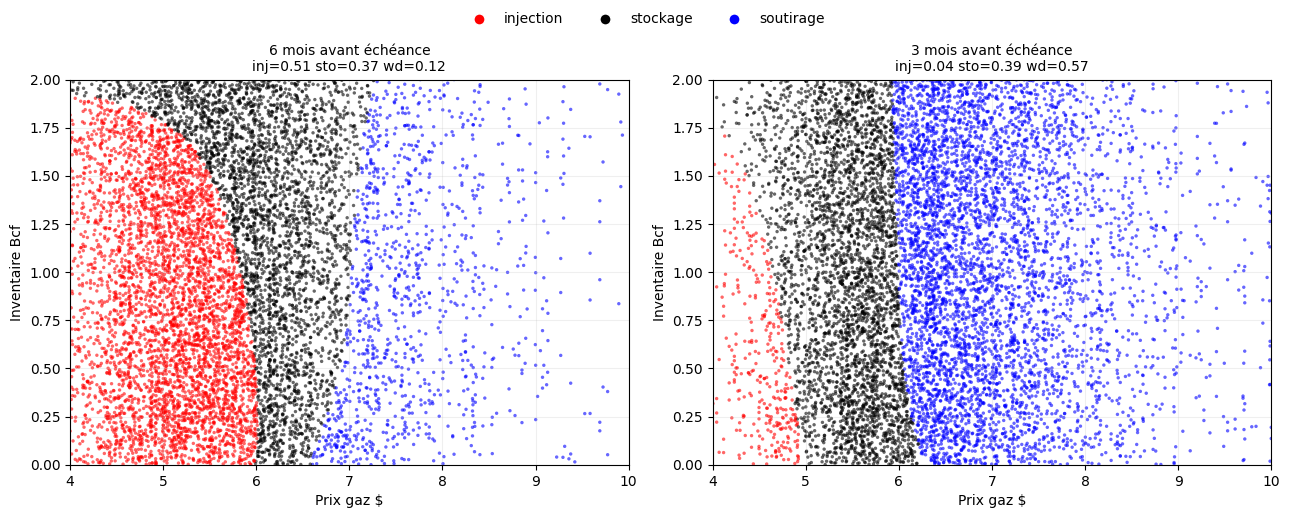

In [11]:
def decide_ex2(phys, cont_coefs, cfg, P, t_query_months, rng, n=9000):
    """Échantillonne (g,c) à l'instant t = T - t_query_months/12 et renvoie la décision
    optimale. Convention corrigée : cont_coefs[j][m_idx] @ base(G[m_idx]), sans disc ni m+1."""
    M=cfg["M"]; dt=P["T"]/M
    G=phys["simulate"](M,cfg["N"],np.random.default_rng(7))
    m_idx=max(0,min(M-1,int(round((P["T"]-t_query_months/12.0)/dt))))
    g=rng.choice(G[m_idx],n); c=rng.uniform(0,P["C_max"],n); qs=np.empty((3,n))
    for k,j in enumerate(REG):
        cf,cn=phys["step"](j,g,c,dt)
        cont=phys["basis"](g,cn,m_idx*dt)@cont_coefs[j][m_idx]   # <-- sans biais de clairvoyance
        qs[k]=cf+cont
    return g,c,np.array(REG)[qs.argmax(0)]

fig,axes=plt.subplots(1,2,figsize=(13,5.2))
for ax,months in zip(axes,[6,3]):
    g,c,d=decide_ex2(phys2,cc2,cfg2,P2,months,np.random.default_rng(6))
    col=np.where(d==-1,"red",np.where(d==0,"black","blue"))
    ax.scatter(g,c,c=col,s=6,alpha=0.6,edgecolors="none")
    ax.set_xlim(4,10); ax.set_ylim(0,2); ax.set_xlabel("Prix gaz $"); ax.set_ylabel("Inventaire Bcf")
    fr=[(d==v).mean() for v in REG]
    ax.set_title(f"{months} mois avant échéance\ninj={fr[0]:.2f} sto={fr[1]:.2f} wd={fr[2]:.2f}",fontsize=10); ax.grid(alpha=.2)
leg=[Line2D([0],[0],marker='o',color='w',markerfacecolor=cc,label=l,markersize=8)
     for cc,l in [("red","injection"),("black","stockage"),("blue","soutirage")]]
fig.legend(handles=leg,loc="upper center",ncol=3,frameon=False)
plt.tight_layout(rect=[0,0,1,0.95]); plt.show()

## 7. Politique optimale selon la phase saisonnière

 On choisit trois instants par leur position dans le cycle saisonnier (pente $\cos(\omega t)$ du niveau moyen) plutôt qu'à des dates arbitraires. La politique optimale doit *suivre* la saison : injecter en phase **montante** (accumuler pour revendre), soutirer en phase **descendante** (vendre avant la baisse), stocker au **pic**. Décision sans look-ahead.

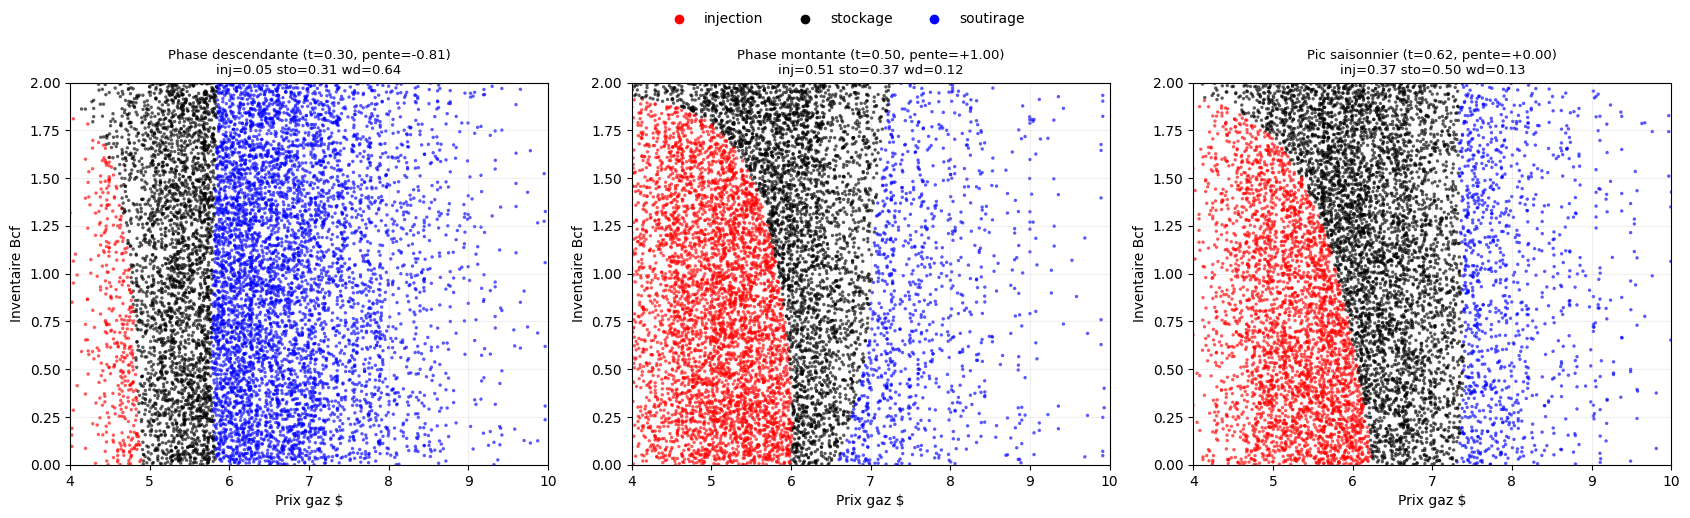

In [12]:
G_ph=phys2["simulate"](cfg2["M"],cfg2["N"],np.random.default_rng(7))
dt_ph=P2["T"]/cfg2["M"]
phases=[(0.30,"Phase descendante"),(0.50,"Phase montante"),(0.625,"Pic saisonnier")]

fig,axes=plt.subplots(1,3,figsize=(17,5.2))
for ax,(tt,lab) in zip(axes,phases):
    mi=max(0,min(cfg2["M"]-1,int(round(tt/dt_ph))))
    rr=np.random.default_rng(int(tt*1000))
    g=rr.choice(G_ph[mi],9000); c=rr.uniform(0,2,9000); qs=np.empty((3,9000))
    for k,j in enumerate(REG):
        cf,cn=phys2["step"](j,g,c,dt_ph)
        cont=phys2["basis"](g,cn,mi*dt_ph)@cc2[j][mi]   # <-- corrigé : [mi], pas [mi+1]
        qs[k]=cf+cont
    d=np.array(REG)[qs.argmax(0)]; fr=[(d==v).mean() for v in REG]
    pente=np.cos(P2["season_freq"]*tt)
    col=np.where(d==-1,"red",np.where(d==0,"black","blue"))
    ax.scatter(g,c,c=col,s=6,alpha=0.65,edgecolors="none")
    ax.set_xlim(4,10); ax.set_ylim(0,2)
    ax.set_xlabel("Prix gaz $"); ax.set_ylabel("Inventaire Bcf")
    ax.set_title(f"{lab} (t={tt:.2f}, pente={pente:+.2f})\ninj={fr[0]:.2f} sto={fr[1]:.2f} wd={fr[2]:.2f}",fontsize=9.5)
    ax.grid(alpha=.2)
leg=[Line2D([0],[0],marker='o',color='w',markerfacecolor=cc,label=l,markersize=8)
     for cc,l in [("red","injection"),("black","stockage"),("blue","soutirage")]]
fig.legend(handles=leg,loc="upper center",ncol=3,frameon=False)
plt.tight_layout(rect=[0,0,1,0.94]); plt.show()

## 8. Surfaces de valeur et frontières — Exemple 1

Helpers branchés sur le moteur : on **lit** `cont_coefs` (algèbre, surfaces/frontières) et la trace du forward instrumenté (`record=True`, nuage Monte-Carlo). Aucune logique de décision n'est ré-implémentée ici — tout vient du moteur.

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap

CASES = {"Cas 1 (débits forts)":   dict(a_in=0.06*365, a_out=0.25*365),
         "Cas 2 (débits faibles)": dict(a_in=0.03*365, a_out=0.125*365)}
T_SLICE, G_RANGE, N_MESH, SEEDF = 0.5, (1.0, 7.0), 60, 83

def _train(cp, deg, n_grid=40, N=2000):
    p=dict(BASE, **cp); set_degree(p, deg); phys=make_ex1(p)
    cfg={"M":250,"N":N,"N_eval":8000,"n_grid":n_grid,"degree":deg,"ridge":1e-4}
    cc=train_backward(phys, cfg, np.random.default_rng(SEEDF), use_quasi=False)
    return phys, cc, cfg

def _mslice(phys, cfg, t): return max(0, min(cfg["M"]-1, int(round(t/(phys["T"]/cfg["M"])))))
def _grid(phys):
    g=np.linspace(*G_RANGE, N_MESH); c=np.linspace(0, phys["C_max"], N_MESH); return np.meshgrid(g,c)

def compute_surface(phys, cc, cfg, regime=0):
    m_t=_mslice(phys, cfg, T_SLICE); GG,CC=_grid(phys)
    V=(phys["basis"](GG.ravel(),CC.ravel(),T_SLICE)@cc[regime][m_t]).reshape(GG.shape)
    _,tr=value_forward_vec(phys, cc, cfg, np.random.default_rng(7), record=True)
    return {"GG":GG,"CC":CC,"V":V,"mc_g":tr["g"][m_t],"mc_c":tr["c"][m_t],
            "deg":cfg["degree"],"ampl":(V.min(),V.max())}

def compute_frontier(phys, cc4, cfg4, cc8, cfg8):
    GG,CC=_grid(phys); dt=phys["T"]/cfg8["M"]
    def policy(cc, m):
        qs=[]
        for j in (-1,0,1):
            cflow,cn=phys["step"](j, GG.ravel(), CC.ravel(), dt)
            qs.append(cflow + phys["basis"](GG.ravel(), cn, T_SLICE)@cc[j][m])
        return np.array(qs).argmax(0).reshape(GG.shape).astype(float)
    _,tr=value_forward_vec(phys, cc8, cfg8, np.random.default_rng(7), record=True)
    m8=_mslice(phys,cfg8,T_SLICE)
    return {"GG":GG,"CC":CC,"POL4":policy(cc4,_mslice(phys,cfg4,T_SLICE)),
            "POL8":policy(cc8,m8),"mc_g":tr["g"][m8],"mc_c":tr["c"][m8]}

def draw_surface(ax, S, title=""):
    ax.plot_surface(S["CC"],S["GG"],S["V"],cmap="bone",edgecolor="none",alpha=0.9,rstride=1,cstride=1)
    ax.scatter(S["mc_c"],S["mc_g"],np.full_like(S["mc_c"],S["V"].min()),s=3,c="crimson",alpha=0.25)
    ax.set_xlabel("Inventaire c",labelpad=8); ax.set_ylabel("Prix g",labelpad=8); ax.set_zlabel("Continuation",labelpad=4)
    ax.set_title(f"{title}deg {S['deg']} — ampl [{S['ampl'][0]:.1f}, {S['ampl'][1]:.1f}]",fontsize=10)
    ax.view_init(elev=22,azim=-130)

def draw_frontier(ax, F, title=""):
    cmap3=ListedColormap(["#2c7fb8","#f0f0f0","#d95f0e"])
    ax.pcolormesh(F["CC"],F["GG"],F["POL8"],cmap=cmap3,shading="auto",alpha=0.45)
    ax.contour(F["CC"],F["GG"],F["POL8"],levels=[0.5,1.5],colors="black",linewidths=2.0)
    ax.contour(F["CC"],F["GG"],F["POL4"],levels=[0.5,1.5],colors="black",linewidths=1.5,linestyles="dashed")
    ax.scatter(F["mc_c"],F["mc_g"],s=4,c="green",alpha=0.25)
    ax.set_xlabel("Inventaire c"); ax.set_ylabel("Prix g")
    ax.set_title(f"{title}plein=deg 8, pointillé=deg 4, vert=MC",fontsize=10)

### Calcul (une seule fois)

Entraînement des moteurs et pré-calcul des surfaces/frontières. Relancer = recalculer. Tant qu'on n'ajuste que l'affichage, inutile de rejouer cette cellule.

In [ ]:
RES_SURF={}; RES_FRONT={}; _eng={}
for cname,cp in CASES.items():
    for deg in (4,8):
        phys,cc,cfg=_train(cp,deg); _eng[(cname,deg)]=(phys,cc,cfg)
        RES_SURF[(cname,deg)]=compute_surface(phys,cc,cfg)
    p4=_eng[(cname,4)]; p8=_eng[(cname,8)]
    RES_FRONT[cname]=compute_frontier(p8[0],p4[1],p4[2],p8[1],p8[2])
print("Calcul figures terminé.")

### Affichage (léger, rejouable)

In [ ]:
# FIGURE 1 — surfaces de continuation, 2 cas x 2 degrés
fig=plt.figure(figsize=(14,11))
for r,cname in enumerate(CASES):
    for col,deg in enumerate((4,8)):
        ax=fig.add_subplot(2,2,r*2+col+1,projection="3d")
        draw_surface(ax, RES_SURF[(cname,deg)], title=f"{cname} — ")
fig.suptitle("Continuation E[V | g,c] au régime store (t=0.5) — rouge = points MC visités",fontsize=12)
plt.tight_layout(); plt.show()

# FIGURE 2 — frontières de switch deg 4 vs deg 8
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax,cname in zip(axes,CASES):
    draw_frontier(ax, RES_FRONT[cname], title=f"{cname}\n")
plt.tight_layout(); plt.show()

## 9. Synthèse

- **Moteur BLSM à régression découplée** : la phase *backward* régresse l'espérance de continuation pure ;
  la phase *forward* décide out-of-sample en lisant ces coefficients au prix présent. Le biais de
  clairvoyance est éliminé par construction.
- **Validation (Tables 3 et 4)** : reproduction des valeurs de Carmona–Ludkovski ; les monotonies
  économiques (capacité ↗, coût de switch ↘, coût de stockage ↘) sont respectées.
- **Exemple 2 saisonnier** : la politique optimale suit la phase saisonnière (injection en phase montante,
  soutirage en phase descendante, stockage au pic) — résultat obtenu sans look-ahead.
- **Estimateurs** : le *forward* (borne inférieure propre) est l'estimateur principal ; le *TViR*,
  ponctuel, sert de contrôle et reste sous le forward (biais bas structurel de Longstaff–Schwartz).

---
*Les études de sensibilité détaillées (degré de base, convergence, diagnostic TViR, profil de risque)
figurent en annexe ci-dessous.*

---
# Annexe — Diagnostics et études de sensibilité

<div style="background:#fff3cd;border:1px solid #ffc107;padding:10px;border-radius:5px">
<b>⚠️ Section optionnelle et coûteuse.</b> Les cellules ci-dessous (multi-graines, grands
<code>N_eval</code>, balayages de degré) peuvent prendre plusieurs minutes chacune. Elles ne sont pas
nécessaires aux résultats du corps principal ; elles documentent le protocole de validation.
</div>

Statuts : ces analyses justifient les choix du corps (degré 4, estimateur forward, abandon du *quasi*).

### A1. Comparaison des trois schémas (multi-graines)

TViR vs BLSM-forward vs BLSM-quasi sur le cas de référence. Montre que le TViR est biaisé bas et que le *quasi* n'apporte rien (d'où son abandon dans le corps).

In [13]:
import time
def run_one(scheme, p_base, cfg, seed):
    p=dict(p_base); set_degree(p,cfg["degree"]); phys=make_ex1(p); t0=time.time()
    if scheme=="tvr":
        c=train_backward(phys,cfg,np.random.default_rng(seed),use_quasi=False); v=value_tvr(phys,c)
    elif scheme=="grille":
        c=train_backward(phys,cfg,np.random.default_rng(seed),use_quasi=False); v=value_forward_vec(phys,c,cfg,np.random.default_rng(seed+1000)).mean()
    else:
        c=train_backward(phys,cfg,np.random.default_rng(seed),use_quasi=True);  v=value_forward_vec(phys,c,cfg,np.random.default_rng(seed+1000)).mean()
    return v, time.time()-t0

def multiseed(scheme, p_base, cfg, nseeds=6):
    vs=[run_one(scheme,p_base,cfg,83+s)[0] for s in range(nseeds)]
    vs=np.array(vs); return vs.mean(), 1.96*vs.std(ddof=1)/np.sqrt(nseeds)

P_CMP=dict(BASE, a_in=0.06*365, a_out=0.25*365); TARGET=9.35
cfg_cmp={"M":200,"N":1200,"N_eval":4000,"n_grid":22,"degree":4,"ridge":1e-4}
print(f"{'schéma':>14}{'V0':>9}{'±IC95':>9}{'biais':>9}")
for sch,lab in [("tvr","TViR"),("grille","BLSM-forward"),("quasi","BLSM-quasi")]:
    m,ic=multiseed(sch,P_CMP,cfg_cmp,nseeds=6)
    print(f"{lab:>14}{m:>9.3f}{ic:>9.3f}{(m-TARGET)/TARGET*100:>+7.1f}%")

        schéma       V0    ±IC95    biais
          TViR    9.219    0.057   -1.4%
  BLSM-forward    9.287    0.056   -0.7%
    BLSM-quasi    9.293    0.054   -0.6%


### A2. Diagnostic du TViR au point initial

Décompose le $\arg\max$ des trois régimes au point de départ pour le cas sain vs le cas à petits débits. Montre que l'écart TViR/forward ne vient pas d'une indétermination d'argmax mais du niveau de la continuation régressée.

### A3. Sensibilité au degré de base (cas 2)

Tendance du forward et du TViR quand on enrichit la base, sur le cas à petits débits. Version légère (mono-graine) ; pour la précision finale, augmenter `N_eval` et moyenner sur graines.

In [14]:
import numpy as np

def test_tvr_indetermination(p_base, cfg, target_make, seed=83, verbose=True):
    """
    Décompose le argmax du TViR au point initial (g0, C0, t=0).
    Si les trois q sont quasi-égaux, le choix de régime est numériquement
    indéterminé : une erreur infime sur cont_coefs domine la vraie
    différence de continuation -> effondrement du TViR ponctuel.
    """
    p = dict(p_base); set_degree(p, cfg["degree"])
    phys = target_make(p)
    M = cfg["M"]; dt = phys["T"] / M

    # Backward corrigé -> cont_coefs (continuations pures, non-anticipatives)
    cont_coefs = train_backward(phys, cfg, np.random.default_rng(seed), use_quasi=False)

    g0 = np.array([phys["price0"]])
    c0 = np.array([phys["C0"]])
    i0 = phys["regime0"]

    rows = []
    for j in (-1, 0, 1):
        cf, cn = phys["step"](j, g0, c0, dt)
        sw = phys["K_switch"] if i0 != j else 0.0
        cont = phys["basis"](g0, cn, 0.0) @ cont_coefs[j][0]
        q = (cf - sw + cont)[0]
        rows.append((j, cf[0], cn[0], sw, cont[0], q))

    qs = np.array([r[5] for r in rows])
    best = qs.argmax()
    spread_abs = qs.max() - qs.min()
    spread_rel = spread_abs / (abs(qs.max()) + 1e-12)

    if verbose:
        print(f"{'régime j':>9}{'cf':>12}{'cn':>10}{'switch':>9}{'cont':>12}{'q':>12}")
        print("-" * 64)
        for (j, cf, cn, sw, cont, q) in rows:
            mark = "  <-- argmax" if j == (-1, 0, 1)[best] else ""
            print(f"{j:>9}{cf:>12.5f}{cn:>10.5f}{sw:>9.3f}{cont:>12.5f}{q:>12.5f}{mark}")
        print("-" * 64)
        print(f"écart absolu max(q)-min(q) : {spread_abs:.5f}")
        print(f"écart relatif              : {spread_rel*100:.3f} %")
        print(f"écart inventaire cn (3 rég): {max(r[2] for r in rows)-min(r[2] for r in rows):.6f}"
              f"  (C_max={phys['C_max']:.2f})")
        diag = ("INDÉTERMINÉ : les régimes sont numériquement équivalents au "
                "point initial -> argmax fragile" if spread_rel < 0.01
                else "Régimes bien différenciés -> argmax robuste")
        print(f"\nDIAGNOSTIC : {diag}")

    return {"qs": qs, "spread_abs": spread_abs, "spread_rel": spread_rel, "rows": rows}


# ============================================================
#  Comparaison cas 1 (facile) vs cas 2 (suspect) côte à côte
# ============================================================
cfg = {"M":200, "N":1200, "N_eval":4000, "n_grid":22, "degree":4, "ridge":1e-4}

print("########  CAS 1 : a_in=0.06, a_out=0.25 (débits forts)  ########\n")
P1 = dict(BASE, a_in=0.06*365, a_out=0.25*365)
r1 = test_tvr_indetermination(P1, cfg, make_ex1)

print("\n\n########  CAS 2 : a_in=0.03, a_out=0.125 (débits faibles)  ########\n")
cfg2 = dict(cfg, M=adaptive_M(0.03*365, 0.125*365))  # respecte ton M adaptatif
P2 = dict(BASE, a_in=0.03*365, a_out=0.125*365)
r2 = test_tvr_indetermination(P2, cfg2, make_ex1)

print("\n\n========  SYNTHÈSE  ========")
print(f"Cas 1 (sain)   : écart relatif des q = {r1['spread_rel']*100:6.3f} %")
print(f"Cas 2 (suspect): écart relatif des q = {r2['spread_rel']*100:6.3f} %")
print(f"\nRatio de fragilité (cas1/cas2) : {r1['spread_rel']/max(r2['spread_rel'],1e-12):.1f}x")

########  CAS 1 : a_in=0.06, a_out=0.25 (débits forts)  ########

 régime j          cf        cn   switch        cont           q
----------------------------------------------------------------
       -1    -0.33050   4.10950    0.250     9.78665     9.20615
        0    -0.00200   4.00000    0.000     9.20836     9.20636  <-- argmax
        1     1.36675   3.54375    0.250     7.70278     8.81953
----------------------------------------------------------------
écart absolu max(q)-min(q) : 0.38684
écart relatif              : 4.202 %
écart inventaire cn (3 rég): 0.565750  (C_max=8.00)

DIAGNOSTIC : Régimes bien différenciés -> argmax robuste


########  CAS 2 : a_in=0.03, a_out=0.125 (débits faibles)  ########

 régime j          cf        cn   switch        cont           q
----------------------------------------------------------------
       -1    -0.08312   4.02738    0.250     3.78191     3.44878
        0    -0.00100   4.00000    0.000     3.47302     3.47202  <-- argmax
     

In [15]:
print("Cas 2 — forward & TViR vs degré (mono-graine, rapide)")
P2c=dict(BASE, a_in=0.03*365, a_out=0.125*365); M2=adaptive_M(0.03*365,0.125*365)
print(f"{'degré':>6}{'forward':>10}{'TViR':>9}")
for deg in (4,6,8):
    cfgd={"M":M2,"N":1200,"N_eval":8000,"degree":deg,"n_grid":22,"ridge":1e-4}
    phys=make_ex1(set_degree(dict(P2c),deg))
    cc=train_backward(phys,cfgd,np.random.default_rng(83),use_quasi=False)
    fwd=value_forward_vec(phys,cc,cfgd,np.random.default_rng(1083)).mean()
    print(f"{deg:>6}{fwd:>10.3f}{value_tvr(phys,cc):>9.3f}")

Cas 2 — forward & TViR vs degré (mono-graine, rapide)
 degré   forward     TViR
     4     4.134    3.472
     6     4.445    3.884
     8     4.619    4.230


     N   lignes       V0    IC95
   500    15000    9.315   0.065
  1000    30000    9.301   0.058
  2000    60000    9.324   0.061
  4000   120000    9.322   0.060
  8000   240000    9.327   0.051


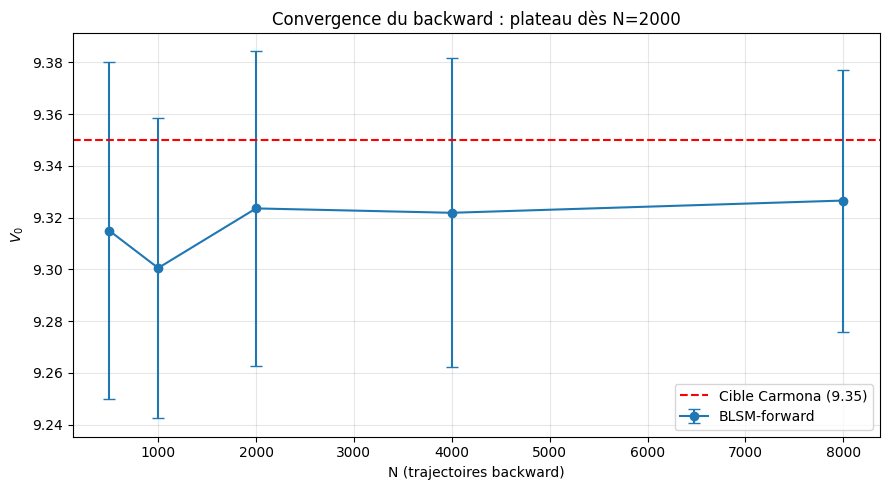

In [16]:
# === ANNEXE — Convergence du backward en N (Modèle 1, cas référence) ===
# Lourd : multi-graines x plusieurs N. Lancer une fois pour la figure 5.1.
P_conv = dict(BASE, a_in=0.06*365, a_out=0.25*365)
cfg_base = {"M":200, "n_grid":30, "degree":4, "ridge":1e-4, "N_eval":8000}
N_values = [500, 1000, 2000, 4000, 8000]

res = []
print(f"{'N':>6}{'lignes':>9}{'V0':>9}{'IC95':>8}")
for N in N_values:
    cfg = dict(cfg_base, N=N)
    vs = []
    for s in range(4):                     # 4 graines
        cc = train_backward(make_ex1(set_degree(dict(P_conv),4)), cfg,
                            np.random.default_rng(83+s), use_quasi=False)
        vs.append(value_forward_vec(make_ex1(set_degree(dict(P_conv),4)), cc, cfg,
                                    np.random.default_rng(184+s)).mean())
    vs = np.array(vs); m = vs.mean(); ic = 1.96*vs.std(ddof=1)/np.sqrt(len(vs))
    res.append((N, m, ic)); print(f"{N:>6}{N*30:>9}{m:>9.3f}{ic:>8.3f}")

res = np.array(res)
plt.figure(figsize=(9,5))
plt.errorbar(res[:,0], res[:,1], yerr=res[:,2], fmt='o-', capsize=4, label="BLSM-forward")
plt.axhline(9.35, color='r', ls='--', label="Cible Carmona (9.35)")
plt.xlabel("N (trajectoires backward)"); plt.ylabel("$V_0$")
plt.title("Convergence du backward : plateau dès N=2000")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

     N   lignes       V0      SD    IC95
---------------------------------------
    50     1500    9.064    4.16   0.041
   100     3000    9.188    4.25   0.042
   200     6000    9.296    4.23   0.041
   400    12000    9.330    4.21   0.041
   800    24000    9.308    4.18   0.041
  1600    48000    9.309    4.19   0.041
  3200    96000    9.301    4.19   0.041


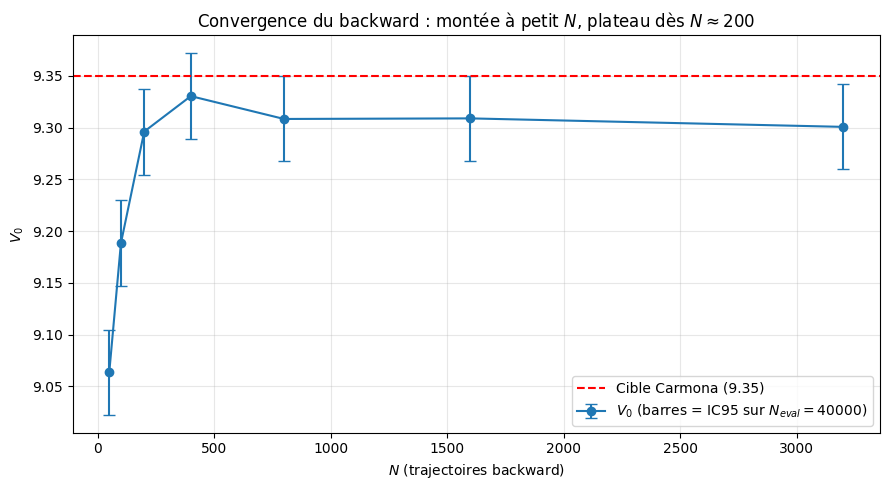

In [17]:
# ============================================================
#  Convergence du backward en N (Modèle 1, cas de référence)
#  - SD  : dispersion réelle des PnL (le RISQUE, ~stable avec N_eval)
#  - IC95 : précision sur la moyenne = 1.96·SD/sqrt(N_eval) (se resserre)
#  Un seul run par N, IC issu des N_eval trajectoires (pas de multi-graines).
# ============================================================
import matplotlib.pyplot as plt

P_conv = dict(BASE, a_in=0.06*365, a_out=0.25*365)
N_values = [50, 100, 200, 400, 800, 1600, 3200]

res = []
print(f"{'N':>6}{'lignes':>9}{'V0':>9}{'SD':>8}{'IC95':>8}")
print("-"*39)
for N in N_values:
    p = dict(P_conv); set_degree(p, 4); phys = make_ex1(p)
    cfg = {"M":200, "N":N, "N_eval":40000, "n_grid":30, "degree":4, "ridge":1e-4}
    cc = train_backward(phys, cfg, np.random.default_rng(83), use_quasi=False)
    m, sd, ic = stats(value_forward_vec(phys, cc, cfg, np.random.default_rng(84)))
    res.append((N, m, sd, ic))
    print(f"{N:>6}{N*30:>9}{m:>9.3f}{sd:>8.2f}{ic:>8.3f}")

res = np.array(res)
plt.figure(figsize=(9, 5))
plt.errorbar(res[:,0], res[:,1], yerr=res[:,3], fmt='o-', capsize=4,
             label="$V_0$ (barres = IC95 sur $N_{eval}=40000$)")
plt.axhline(9.35, color='r', ls='--', label="Cible Carmona (9.35)")
plt.xlabel("$N$ (trajectoires backward)")
plt.ylabel("$V_0$")
plt.title("Convergence du backward : montée à petit $N$, plateau dès $N \\approx 200$")
plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### A4. Distribution du PnL (profil de risque)

Histogramme du P&L réalisé par trajectoire à l'optimum.

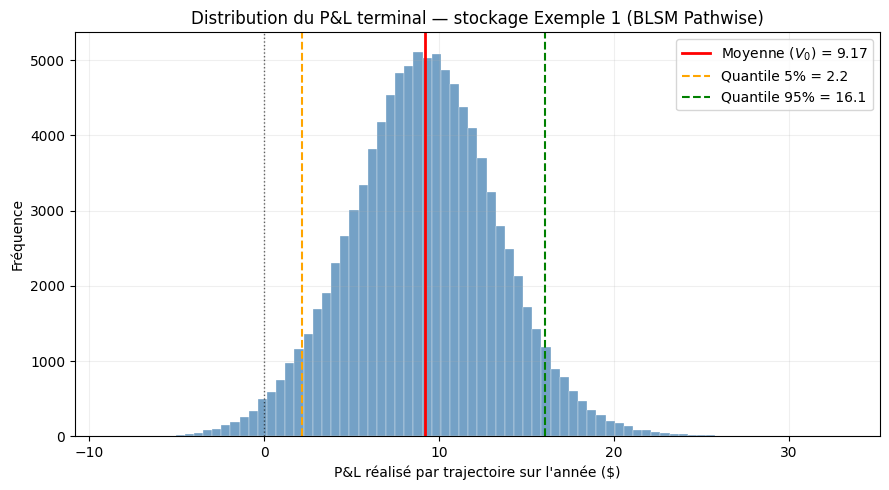

P&L sur l'année : moyenne = 9.17 (= V0)
  écart-type (risque)     : 4.21
  intervalle 5%-95%       : [2.2, 16.1]
  scénarios perdants (<0) : 1.6 %


In [18]:
# ============================================================
#  Distribution du P&L terminal — profil de risque (Exemple 1)
#  Chaque point = P&L total d'UNE année simulée (somme actualisée des
#  cash-flows sur les M pas + pénalité terminale), sous la politique BLSM.
#  N backward = 1000 (politique convergée, au-delà du plateau N~200).
#  N_eval = 100000 pour une distribution finale lisse et des quantiles fiables.
# ============================================================
p_pnl = dict(BASE, a_in=0.06*365, a_out=0.25*365); set_degree(p_pnl, 4)
phys_pnl = make_ex1(p_pnl)
cfg_pnl = {"M":250, "N":200, "N_eval":100000, "n_grid":35, "degree":4, "ridge":1e-4}

coefs_pnl = train_backward(phys_pnl, cfg_pnl, np.random.default_rng(83), use_quasi=False)
pv = value_forward_vec(phys_pnl, coefs_pnl, cfg_pnl, np.random.default_rng(84))

m, sd, ic = stats(pv)
q5, q95 = np.percentile(pv, [5, 95])
p_neg = (pv < 0).mean() * 100   # proportion de scénarios perdants

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(pv, bins=80, color="steelblue", alpha=0.75, edgecolor="white", linewidth=0.3)
ax.axvline(m,   color="red",    lw=2,   label=f"Moyenne ($V_0$) = {m:.2f}")
ax.axvline(q5,  color="orange", ls="--", lw=1.5, label=f"Quantile 5% = {q5:.1f}")
ax.axvline(q95, color="green",  ls="--", lw=1.5, label=f"Quantile 95% = {q95:.1f}")
ax.axvline(0,   color="black",  ls=":",  lw=1,   alpha=0.6)
ax.set_xlabel("P&L réalisé par trajectoire sur l'année ($)")
ax.set_ylabel("Fréquence")
ax.set_title("Distribution du P&L terminal — stockage Exemple 1 (BLSM Pathwise)")
ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print(f"P&L sur l'année : moyenne = {m:.2f} (= V0)")
print(f"  écart-type (risque)     : {sd:.2f}")
print(f"  intervalle 5%-95%       : [{q5:.1f}, {q95:.1f}]")
print(f"  scénarios perdants (<0) : {p_neg:.1f} %")

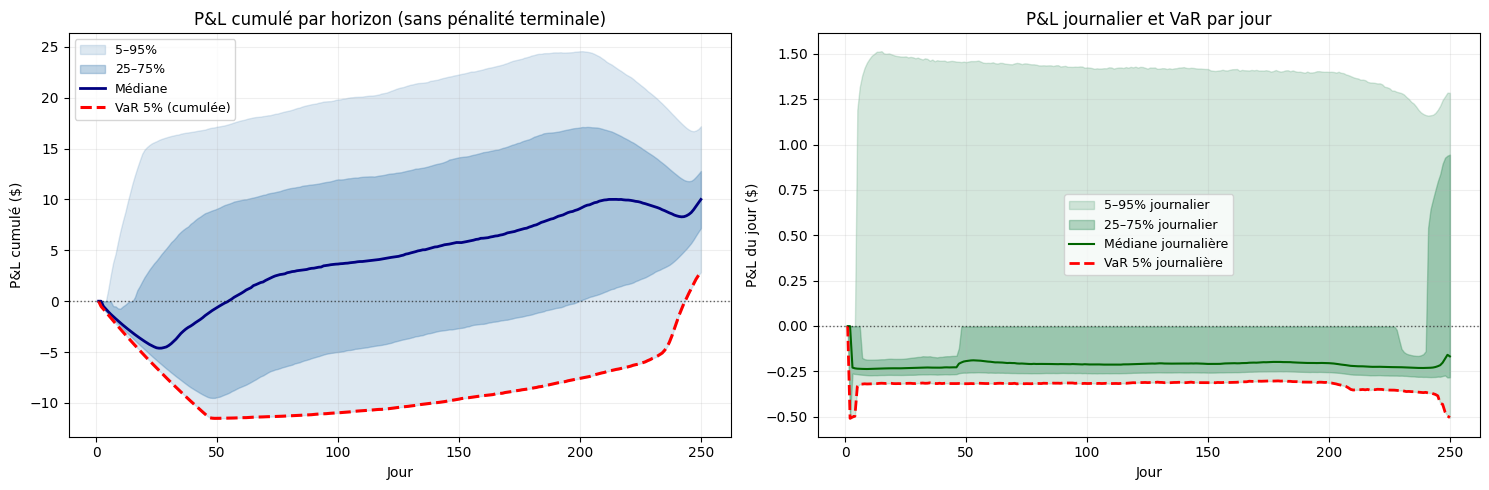

VaR 5% cumulée finale       : 2.85
VaR 5% journalière (médiane): -0.317
Médiane P&L final           : 10.00


In [19]:
# ============================================================
#  P&L par horizon et VaR par jour — analyse de risque temporel
#  (Exemple 1, SANS pénalité terminale : terminal=0 pour un P&L
#  réalisé propre à chaque horizon, hors validation Carmona).
#
#  - Panneau GAUCHE  : P&L CUMULÉ par horizon (perte/gain si on liquide
#    au jour m). VaR 5% cumulée = perte dans les 5% pires scénarios.
#  - Panneau DROITE  : P&L JOURNALIER (réalisé chaque jour). VaR 5%
#    journalière = perte sur un jour dans les 5% pires cas (VaR de marché).
#
#  style : 1 = fan chart complet (bandes 5-95 / 25-75 + médiane)
#          2 = épuré (médiane + VaR 5% seules)
#          3 = fan chart + VaR 5% en surimpression épaisse
# ============================================================

def value_forward_trace(phys, cont_coefs, cfg, rng):
    """Forward qui stocke le P&L cumulé et incrémental (M, N_eval).
    Pénalité terminale désactivée (analyse de risque propre)."""
    M, N = cfg["M"], cfg["N_eval"]; dt = phys["T"]/M; disc = np.exp(-phys["r"]*dt)
    G = phys["simulate"](M, N, rng)
    c = np.full(N, phys["C0"]); regime = np.full(N, phys["regime0"])
    pv = np.zeros(N); df = 1.0
    pnl_cum = np.empty((M, N)); pnl_step = np.empty((M, N))
    for m in range(M):
        qs = np.empty((3, N)); cfs = np.empty((3, N)); cns = np.empty((3, N))
        for k, j in enumerate(REG):
            cf, cn = phys["step"](j, G[m], c, dt)
            ec = phys["basis"](G[m], cn, m*dt) @ cont_coefs[j][m]
            sw = np.where(regime == j, 0.0, phys["K_switch"])
            qs[k] = cf - sw + ec; cfs[k] = cf - sw; cns[k] = cn
        b = qs.argmax(0); idx = np.arange(N); step_cf = df * cfs[b, idx]
        pv += step_cf; pnl_cum[m] = pv; pnl_step[m] = step_cf
        c = cns[b, idx]; regime = np.array(REG)[b]; df *= disc
    return pnl_cum, pnl_step


def plot_pnl_horizon(pnl_cum, pnl_step, style=3):
    M = pnl_cum.shape[0]; days = np.arange(1, M + 1)
    qc = {q: np.percentile(pnl_cum,  q, axis=1) for q in (5, 25, 50, 75, 95)}
    qs = {q: np.percentile(pnl_step, q, axis=1) for q in (5, 25, 50, 75, 95)}
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # ---------- GAUCHE : P&L cumulé ----------
    ax = axes[0]
    if style in (1, 3):
        ax.fill_between(days, qc[5], qc[95], alpha=0.18, color="steelblue", label="5–95%")
        ax.fill_between(days, qc[25], qc[75], alpha=0.35, color="steelblue", label="25–75%")
    ax.plot(days, qc[50], color="navy", lw=2, label="Médiane")
    if style in (2, 3):
        lw = 2.2 if style == 3 else 1.6
        ax.plot(days, qc[5], color="red", lw=lw, ls="--", label="VaR 5% (cumulée)")
    ax.axhline(0, color="black", ls=":", lw=1, alpha=0.6)
    ax.set_xlabel("Jour"); ax.set_ylabel("P&L cumulé ($)")
    ax.set_title("P&L cumulé par horizon (sans pénalité terminale)")
    ax.legend(fontsize=9); ax.grid(alpha=0.2)

    # ---------- DROITE : P&L journalier ----------
    ax = axes[1]
    if style in (1, 3):
        ax.fill_between(days, qs[5], qs[95], alpha=0.20, color="seagreen", label="5–95% journalier")
        ax.fill_between(days, qs[25], qs[75], alpha=0.35, color="seagreen", label="25–75% journalier")
    ax.plot(days, qs[50], color="darkgreen", lw=1.5, label="Médiane journalière")
    if style in (2, 3):
        lw = 2.0 if style == 3 else 1.4
        ax.plot(days, qs[5], color="red", lw=lw, ls="--", label="VaR 5% journalière")
    ax.axhline(0, color="black", ls=":", lw=1, alpha=0.6)
    ax.set_xlabel("Jour"); ax.set_ylabel("P&L du jour ($)")
    ax.set_title("P&L journalier et VaR par jour")
    ax.legend(fontsize=9); ax.grid(alpha=0.2)

    plt.tight_layout(); plt.show()
    print(f"VaR 5% cumulée finale       : {qc[5][-1]:.2f}")
    print(f"VaR 5% journalière (médiane): {np.median(qs[5]):.3f}")
    print(f"Médiane P&L final           : {qc[50][-1]:.2f}")


# --- exécution ---
p_h = dict(BASE, a_in=0.06*365, a_out=0.25*365); set_degree(p_h, 4)
phys_h = make_ex1(p_h)
cfg_h = {"M":250, "N":1000, "N_eval":40000, "n_grid":35, "degree":4, "ridge":1e-4}
coefs_h = train_backward(phys_h, cfg_h, np.random.default_rng(83), use_quasi=False)
pnl_cum, pnl_step = value_forward_trace(phys_h, coefs_h, cfg_h, np.random.default_rng(84))

# change style ici : 1 (fan), 2 (épuré), 3 (fan + VaR)
plot_pnl_horizon(pnl_cum, pnl_step, style=3)

In [ ]:
#plot_pnl_horizon(pnl_cum, pnl_step, style=1)

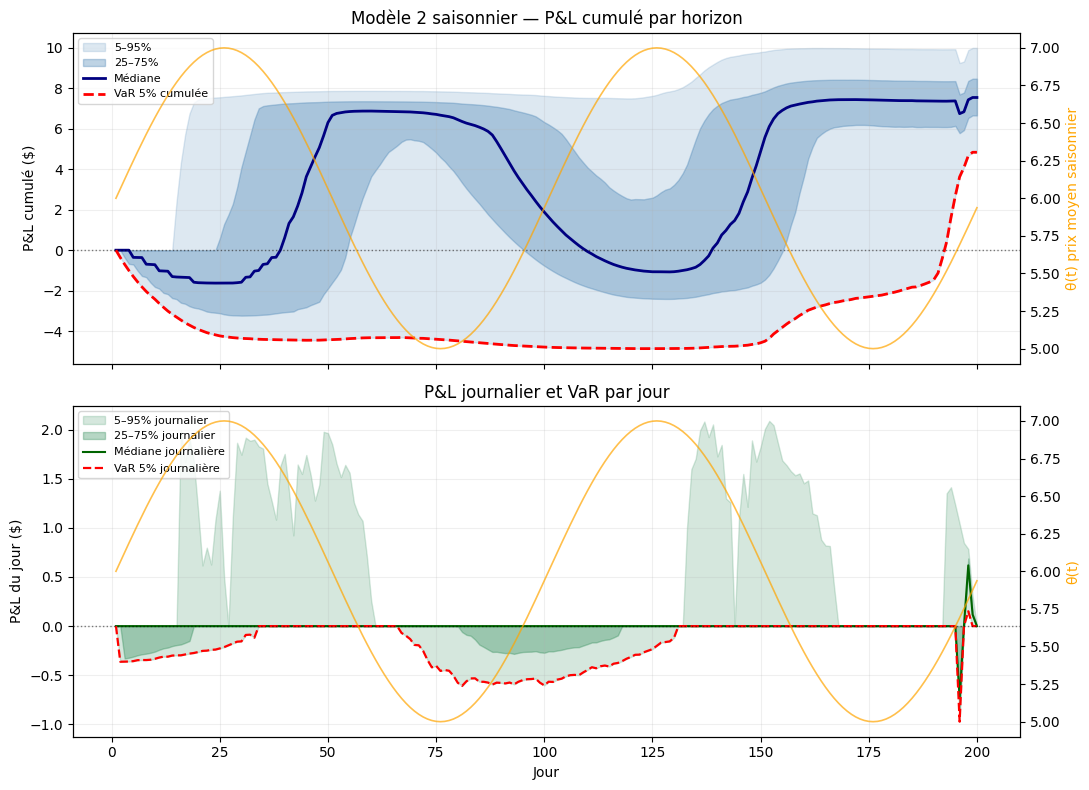

P&L cumulé médian final : 7.55
VaR 5% cumulée finale   : 4.84
nombre de cycles saisonniers : 2.0


In [35]:
# ============================================================
#  P&L par horizon et VaR par jour — Modèle 2 SAISONNIER
#  (terminal=0 : analyse de risque propre). Le cycle saisonnier
#  theta(t) est superposé (orange) pour lire la synchronisation.
#
#  Lecture : le P&L cumulé monte EN MARCHES, une par cycle (on achète
#  au creux, on vend au pic). Le P&L journalier PULSE : salves de gains
#  pendant les phases de soutirage, P&L nul pendant l'attente. Le risque
#  (VaR journalière) se creuse en phase d'injection, remonte en soutirage.
# ============================================================


# Paramètres du Modèle 2 SAISONNIER (à redéfinir, le nom P2 a été écrasé)
P2_saison = {"a_mr":4.0, "season_amp":1.0, "season_base":6.0, "season_freq":4.0*np.pi,
             "sigma":0.5, "G0":6.0, "C_max":2.0, "C0":1.0, "gas_loss":0.0017*365.0,
             "r":0.10, "T":1.0}
set_degree(P2_saison, 4)
phys2_saison = make_ex2(P2_saison)

def value_forward_trace(phys, cont_coefs, cfg, rng):
    """Forward stockant le P&L cumulé et incrémental (terminal=0)."""
    M, N = cfg["M"], cfg["N_eval"]; dt = phys["T"]/M; disc = np.exp(-phys["r"]*dt)
    G = phys["simulate"](M, N, rng)
    c = np.full(N, phys["C0"]); regime = np.full(N, phys["regime0"])
    pv = np.zeros(N); df = 1.0
    pnl_cum = np.empty((M, N)); pnl_step = np.empty((M, N))
    for m in range(M):
        qs = np.empty((3, N)); cfs = np.empty((3, N)); cns = np.empty((3, N))
        for k, j in enumerate(REG):
            cf, cn = phys["step"](j, G[m], c, dt)
            ec = phys["basis"](G[m], cn, m*dt) @ cont_coefs[j][m]
            sw = np.where(regime == j, 0.0, phys["K_switch"])
            qs[k] = cf - sw + ec; cfs[k] = cf - sw; cns[k] = cn
        b = qs.argmax(0); idx = np.arange(N); step_cf = df * cfs[b, idx]
        pv += step_cf; pnl_cum[m] = pv; pnl_step[m] = step_cf
        c = cns[b, idx]; regime = np.array(REG)[b]; df *= disc
    return pnl_cum, pnl_step


def plot_pnl_saison(pnl_cum, pnl_step, params, style=3):
    M = pnl_cum.shape[0]; days = np.arange(1, M + 1); dt = params["T"]/M
    tt = np.arange(M) * dt
    theta_t = params["season_base"] + params["season_amp"] * np.sin(params["season_freq"] * tt)
    qc = {q: np.percentile(pnl_cum,  q, axis=1) for q in (5, 25, 50, 75, 95)}
    qs = {q: np.percentile(pnl_step, q, axis=1) for q in (5, 25, 50, 75, 95)}
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # --- haut : P&L cumulé ---
    ax = axes[0]
    if style in (1, 3):
        ax.fill_between(days, qc[5], qc[95], alpha=0.18, color="steelblue", label="5–95%")
        ax.fill_between(days, qc[25], qc[75], alpha=0.35, color="steelblue", label="25–75%")
    ax.plot(days, qc[50], color="navy", lw=2, label="Médiane")
    if style in (2, 3):
        ax.plot(days, qc[5], color="red", lw=2.0, ls="--", label="VaR 5% cumulée")
    ax.axhline(0, color="k", ls=":", lw=1, alpha=.5)
    ax2 = ax.twinx(); ax2.plot(days, theta_t, color="orange", lw=1.2, alpha=0.7)
    ax2.set_ylabel("θ(t) prix moyen saisonnier", color="orange")
    ax.set_ylabel("P&L cumulé ($)")
    ax.set_title("Modèle 2 saisonnier — P&L cumulé par horizon")
    ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.2)

    # --- bas : P&L journalier ---
    ax = axes[1]
    if style in (1, 3):
        ax.fill_between(days, qs[5], qs[95], alpha=0.2, color="seagreen", label="5–95% journalier")
        ax.fill_between(days, qs[25], qs[75], alpha=0.35, color="seagreen", label="25–75% journalier")
    ax.plot(days, qs[50], color="darkgreen", lw=1.5, label="Médiane journalière")
    if style in (2, 3):
        ax.plot(days, qs[5], color="red", lw=1.6, ls="--", label="VaR 5% journalière")
    ax.axhline(0, color="k", ls=":", lw=1, alpha=.5)
    ax3 = ax.twinx(); ax3.plot(days, theta_t, color="orange", lw=1.2, alpha=0.7)
    ax3.set_ylabel("θ(t)", color="orange")
    ax.set_xlabel("Jour"); ax.set_ylabel("P&L du jour ($)")
    ax.set_title("P&L journalier et VaR par jour")
    ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.2)

    plt.tight_layout(); plt.show()
    print(f"P&L cumulé médian final : {qc[50][-1]:.2f}")
    print(f"VaR 5% cumulée finale   : {qc[5][-1]:.2f}")
    print(f"nombre de cycles saisonniers : {params['season_freq']*params['T']/(2*np.pi):.1f}")


# --- exécution sur le Modèle 2 (réutilise phys2, P2 du notebook gelé) ---
cfg_s = {"M":200, "N":1000, "N_eval":40000, "n_grid":40, "degree":4, "ridge":1e-5}
coefs_s = train_backward(phys2_saison, cfg_s, np.random.default_rng(7), use_quasi=False)
pnl_cum_s, pnl_step_s = value_forward_trace(phys2_saison, coefs_s, cfg_s, np.random.default_rng(8))
plot_pnl_saison(pnl_cum_s, pnl_step_s, P2_saison, style=3)